In [2]:
!pip install tensorflow numpy matplotlib -q

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

print("🧠 LSTM FRAMEWORK ")
print(f"TensorFlow: {tf.__version__}")



🧠 LSTM FRAMEWORK 
TensorFlow: 2.19.0


In [3]:

# 1. Point to your RAW FYP-1 CMAPSS dataset
# (Make sure train_FD001.txt is inside your data folder!)
DATA_PATH = "train_FD001.txt"

print("Loading Raw CMAPSS Text Data...")
# We use sep='\s+' because the text file uses multiple spaces as separators
df = pd.read_csv(DATA_PATH, sep='\s+', header=None)

# 2. Assign the exact column names you used in FYP-1
columns = [
    'unit', 'cycle',
    'op1', 'op2', 'op3',
    'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5',
    'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10',
    'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15',
    'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20',
    'sensor_21'
]

# The raw text file has trailing spaces that create empty columns at the end.
# We slice only the first 28 columns, then assign names.
df = df.iloc[:, :28]
df.columns = columns



# 4. Calculate the MAX cycles for each specific engine ('unit')
# This tells us exactly when the engine "died"
rul_data = df.groupby('unit')['cycle'].max().reset_index()
rul_data.columns = ['unit', 'max_cycles']

# 5. Merge this back into the main dataset
df = df.merge(rul_data, on=['unit'], how='left')

# 6. Calculate the TRUE Remaining Useful Life (RUL) for every row
# Formula: RUL = (Total Lifespan) - (Current Cycle)
df['RUL'] = df['max_cycles'] - df['cycle']

# 7. Drop the max_cycles column as we don't need it anymore
df.drop('max_cycles', axis=1, inplace=True)

print("✅ RUL Calculation Complete! Here are the first 5 rows:")
display(df[['unit', 'cycle', 'RUL']].head())

Loading Raw CMAPSS Text Data...
✅ RUL Calculation Complete! Here are the first 5 rows:


<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_4205/2356470682.py:7: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(DATA_PATH, sep='\s+', header=None)


,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


In [4]:
# 1. Define the size of our "Sliding Window" (Looking at 30 flights at a time)
sequence_length = 30

# 2. Separate the features (Sensors) from the identifiers and targets
features = [col for col in df.columns if col not in ['unit', 'cycle', 'RUL']]

def generate_sequences(engine_df, seq_length, feature_cols):
    """
    Slices an engine's flight history into overlapping blocks of `seq_length`.
    """
    engine_data = engine_df[feature_cols].values
    engine_labels = engine_df['RUL'].values

    X_seq = []
    y_seq = []

    # Slide the window down the engine's history
    for i in range(len(engine_data) - seq_length):
        X_seq.append(engine_data[i : i + seq_length])

        # The label is the RUL at the VERY END of this 30-flight window
        y_seq.append(engine_labels[i + seq_length])

    return X_seq, y_seq

print("Processing Sliding Windows for all engines... This might take a few seconds.")

X_train = []
y_train = []

# Loop through every single engine (Units 1 to 100)
for engine_id in df['unit'].unique():
    engine_df = df[df['unit'] == engine_id]

    # Generate the 3D blocks for this specific engine
    X_engine, y_engine = generate_sequences(engine_df, sequence_length, features)

    X_train.extend(X_engine)
    y_train.extend(y_engine)

# Convert lists to NumPy arrays (The required format for Deep Learning)
X_train = np.array(X_train)
y_train = np.array(y_train)

print("\n✅ 3D Conversion Complete!")
print("-" * 50)
print(f"X_train Shape: {X_train.shape} -> (Samples, Time Steps, Sensors)")
print(f"y_train Shape: {y_train.shape} -> (Labels)")
print("-" * 50)

# 3. Save the arrays to disk for Kamal!
np.save('X_train_lstm.npy', X_train)
np.save('y_train_lstm.npy', y_train)

print("💾 Saved as 'X_train_lstm.npy' and 'y_train_lstm.npy' in the data folder.")

Processing Sliding Windows for all engines... This might take a few seconds.

✅ 3D Conversion Complete!
--------------------------------------------------
X_train Shape: (17631, 30, 24) -> (Samples, Time Steps, Sensors)
y_train Shape: (17631,) -> (Labels)
--------------------------------------------------
💾 Saved as 'X_train_lstm.npy' and 'y_train_lstm.npy' in the data folder.


In [5]:
# Load Rayyan/Maiz's EXACT data (17631, 30, 24)
X_lstm = np.load('X_train_lstm.npy')
y_lstm = np.load('y_train_lstm.npy')

print(f"✅ Loaded: X {X_lstm.shape}, y {y_lstm.shape}")
print("Input shape: (30 timesteps, 24 sensors)")

✅ Loaded: X (17631, 30, 24), y (17631,)
Input shape: (30 timesteps, 24 sensors)


In [6]:
# DAY 3 DELIVERABLE: Exact (30,24) input_shape
lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(30, 24)),  # PERFECT MATCH!
    Dropout(0.3),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.1),
    Dense(1, activation='linear')  # RUL in cycles
])

lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

lstm_model.summary()
print("✅ DAY 3 COMPLETE: Architecture ready!")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        22,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,745 (139.63 KB)

 Trainable params: 35,745 (139.63 KB)

 Non-trainable params: 0 (0.00 B)

✅ DAY 3 COMPLETE: Architecture ready!


Training: (14104, 30, 24)
Epoch 1/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - loss: 8500.0508 - mae: 73.7091 - val_loss: 8145.2246 - val_mae: 68.8327
Epoch 2/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 3902.5422 - mae: 49.9992 - val_loss: 5518.3877 - val_mae: 59.0273
Epoch 3/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - loss: 3592.6169 - mae: 48.8833 - val_loss: 5440.4785 - val_mae: 58.8510
Epoch 4/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - loss: 3572.5300 - mae: 48.7877 - val_loss: 5422.7148 - val_mae: 58.8155
Epoch 5/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - loss: 3562.4299 - mae: 48.7891 - val_loss: 5428.6904 - val_mae: 58.8276
Epoch 6/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 3574.1145 - mae: 48.7783 - val_loss: 5427.4658 - val_mae: 58.8251
Epoch 7/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - loss: 3559.5317 - mae: 48.7415 - val_loss: 5412.8110 - val_mae: 58.7951
Epoch 8/15
221/221 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - loss: 3563.0972 - mae: 48.

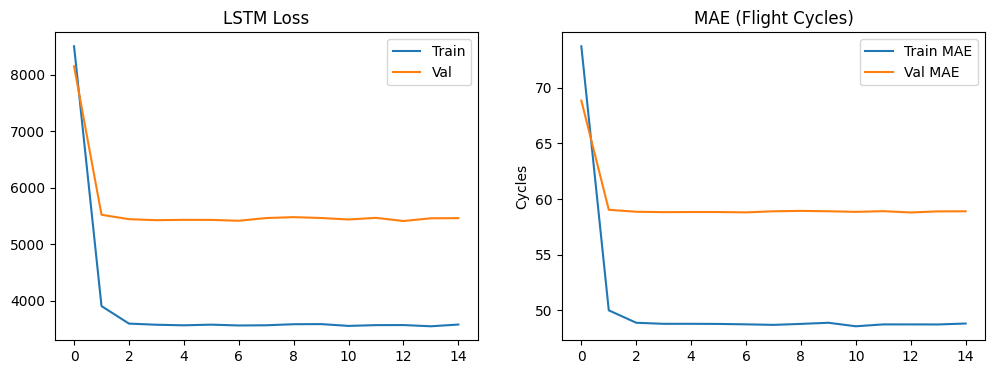

✅ DAY 4 COMPLETE: Training finished!


In [7]:
# Real Train/Val Split
split_idx = int(0.8 * len(X_lstm))
X_train, X_val = X_lstm[:split_idx], X_lstm[split_idx:]
y_train, y_val = y_lstm[:split_idx], y_lstm[split_idx:]

print(f"Training: {X_train.shape}")

# TRAINING LOOP - NO DUMMY DATA!
history = lstm_model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

# Plot Results
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('LSTM Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title('MAE (Flight Cycles)')
plt.ylabel('Cycles')
plt.legend()
plt.savefig('lstm_training.png', dpi=300)
plt.show()

print("✅ DAY 4 COMPLETE: Training finished!")

In [9]:
lstm_model.save('kamal_lstm_fyp2.h5')
np.save('lstm_history.npy', history.history)

# Test single prediction
test_sample = X_lstm[0:1]
rul_pred = lstm_model.predict(test_sample, verbose=0)[0][0]
print(f"✅ Test RUL: {rul_pred:.1f} cycles")
print("✅ LSTM saved: lstm_fyp2.h5")

print("\n🎉 FYP-2 LSTM DELIVERABLE COMPLETE!")

✅ Test RUL: 88.6 cycles
✅ LSTM saved: lstm_fyp2.h5

🎉 FYP-2 LSTM DELIVERABLE COMPLETE!
